<a href="https://colab.research.google.com/github/VictorTrasancos/Sales-radio-RegressionAnalysys/blob/main/Regressao_linear_radio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols
np.random.seed(101)

data = pd.read_csv('Advertising.csv', header=(0), index_col=[0])
data = data[['radio','sales']]
y_label = data.columns[-1]
print('Número de linhas e colunas', data.shape)
data.head()

Número de linhas e colunas (200, 2)


,radio,sales
1,37.8,22.1
2,39.3,10.4
3,45.9,9.3
4,41.3,18.5
5,10.8,12.9


In [14]:
# Ajustando o modelo de regressão linear
modelo = ols('sales ~ radio', data=data).fit()

# Mostra o resumo do modelo
modelo.summary()

#Obtendo os coeficientes
intercepto = modelo.params['Intercept']
coeficiente_radio = modelo.params['radio']

print(f"Intercepto: {intercepto:.4f}")
print(f"Coeficiente do radio: {coeficiente_radio:.4f}")
print('Modelo ajustado:')
print(f'\n sales = {intercepto:.4f} + {coeficiente_radio:.4f} * radio')


Intercepto: 9.3116
Coeficiente do radio: 0.2025
Modelo ajustado:

 sales = 9.3116 + 0.2025 * radio


In [16]:
data['sales_predito'] = modelo.predict(data)
display(data.head(10))

,radio,sales,sales_predito
1,37.8,22.1,16.965979
2,39.3,10.4,17.269722
3,45.9,9.3,18.606195
4,41.3,18.5,17.674714
5,10.8,12.9,11.498593
6,48.9,7.2,19.213682
7,32.8,11.8,15.953500
8,19.6,13.2,13.280555
9,2.1,4.8,9.736879
10,2.6,10.6,9.838127


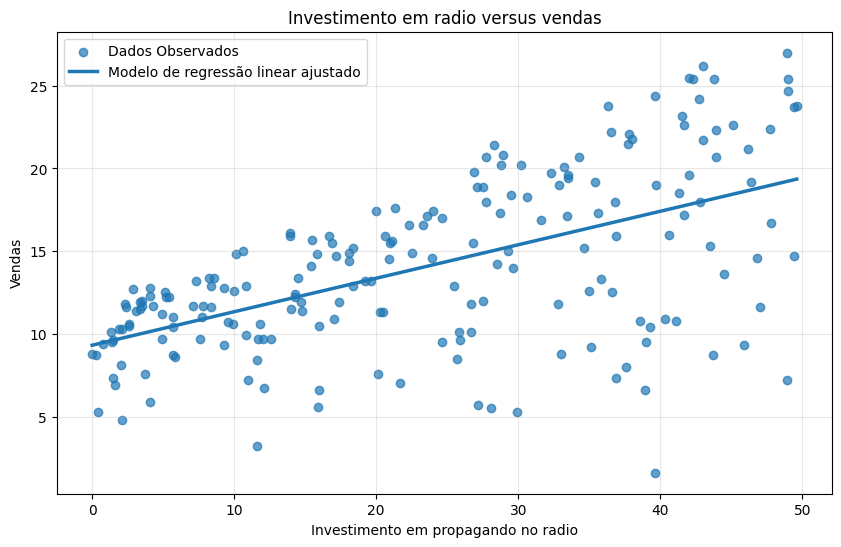

In [17]:
# Ordenando os valores dos dados conforme radio,
# para evitar linhas cruzadas no gráfico
data_ordenado = data.sort_values('radio')

plt.figure(figsize=(10, 6))
# Dados observados
plt.scatter(
    data['radio'],
    data['sales'],
    alpha = 0.7,
    label='Dados Observados'
)
# Reta de Regressão
plt.plot(
    data_ordenado['radio'],
    data_ordenado['sales_predito'],
    linewidth = 2.5,
    label='Modelo de regressão linear ajustado'
)

plt.xlabel('Investimento em propagando no radio')
plt.ylabel('Vendas')
plt.title('Investimento em radio versus vendas')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
#

In [18]:
print(f"R²: {modelo.rsquared:.4f}")
print(f"R² ajustado: {modelo.rsquared_adj:.4f}")
print(f"Erro quadrático médio dos resíduos: {modelo.mse_resid:.4f}")

R²: 0.3320
R² ajustado: 0.3287
Erro quadrático médio dos resíduos: 18.2751
